# Telco Customer Churn Prediction
## End-to-end Machine Learning project

**Goal**: Build a classification model that predicts whether a telecom customer is likely to leave the service.
I also want to understand which customer characteristics are most related to churn and how the prediction threshold affects the results.

Dataset: [Kaggle — Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

This notebook includes data understanding, quality checks, EDA, preprocessing without leakage, a baseline, model comparison, threshold tuning, error analysis, feature importance, and model export.

> The dataset is a historical learning dataset. Results are not a guarantee of performance on current customers or other telecom businesses.


## 1. Imports and configuration

In [49]:
import os, glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    make_scorer,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay, precision_recall_curve
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
import joblib

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 100)


## 2. Load data
In Kaggle, attach the dataset using **Add Input**. The loader searches `/kaggle/input` for the CSV. If running locally, set `CSV_PATH` to your downloaded file.

In [50]:
matches = glob.glob("/kaggle/input/**/WA_Fn-UseC_-Telco-Customer-Churn.csv", recursive=True)
CSV_PATH = matches[0] if matches else None

if CSV_PATH is None:
    # Local fallback: update this path after downloading the CSV.
    CSV_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(CSV_PATH)
print("Loaded:", CSV_PATH)
print("Shape:", df.shape)
display(df.head())


Loaded: /kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Initial data audit

In [51]:
display(df.info())
display(df.describe(include="all").T)
print("Duplicate rows:", df.duplicated().sum())
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Duplicate rows: 0


,missing_count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


## 4. Data cleaning
`TotalCharges` is stored as text in the source and contains whitespace-only entries for some zero-tenure customers. Convert it safely to numeric; retain those rows and impute within the training pipeline. Drop `customerID` from predictors because it is an identifier, not a customer behavior feature.

In [52]:
data = df.copy()
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"].astype(str).str.strip(), errors="coerce")
data["Churn"] = data["Churn"].astype(str).str.strip()

print("TotalCharges missing after conversion:", data["TotalCharges"].isna().sum())
print("Target values:", data["Churn"].value_counts(dropna=False).to_dict())

# Remove rows without a usable target, if any.
data = data[data["Churn"].isin(["Yes", "No"])].copy()
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1}).astype(int)

# Defensive duplicate removal
data = data.drop_duplicates().reset_index(drop=True)
print("Modeling shape:", data.shape)


TotalCharges missing after conversion: 11
Target values: {'No': 5174, 'Yes': 1869}
Modeling shape: (7043, 21)


## 5. Exploratory Data Analysis

,customers
Churn,
No churn,5174
Churn,1869


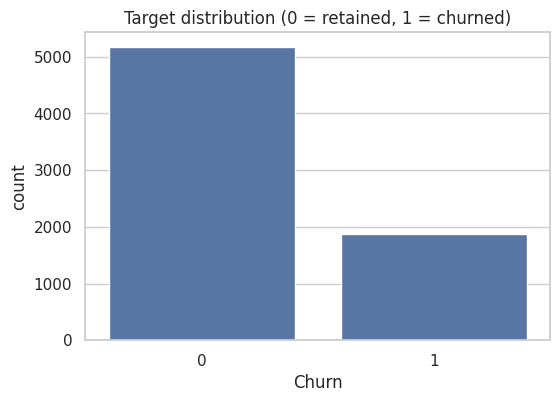

Churn rate: 26.54 %


In [53]:
target_counts = data["Churn"].value_counts().rename(index={0:"No churn", 1:"Churn"})
display(target_counts.to_frame("customers"))
plt.figure(figsize=(6,4))
sns.countplot(data=data, x="Churn")
plt.title("Target distribution (0 = retained, 1 = churned)")
plt.show()
print("Churn rate:", round(data["Churn"].mean()*100, 2), "%")


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80
Churn,7043.0,0.265370,0.441561,0.00,0.00,0.000,1.0000,1.00


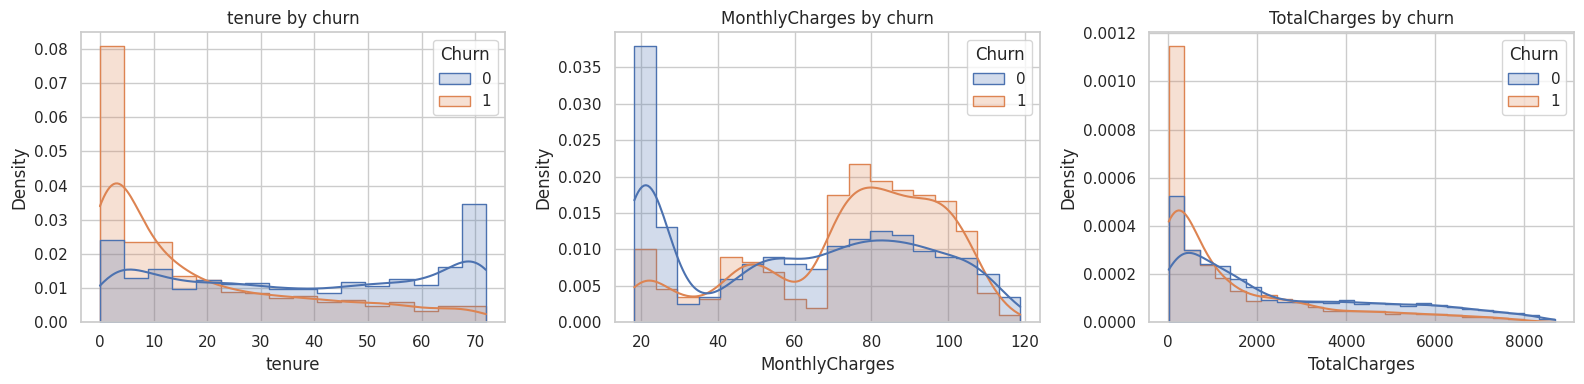

In [54]:
numeric_cols_all = data.select_dtypes(include=np.number).columns.tolist()
display(data[numeric_cols_all].describe().T)

fig, axes = plt.subplots(1, 3, figsize=(16,4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=data, x=col, hue="Churn", kde=True, element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.show()


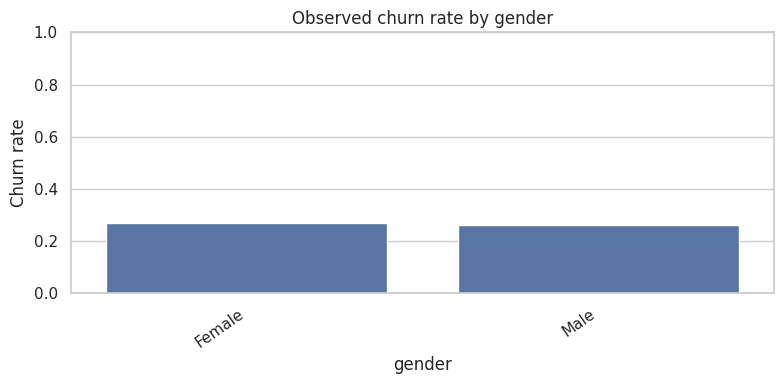

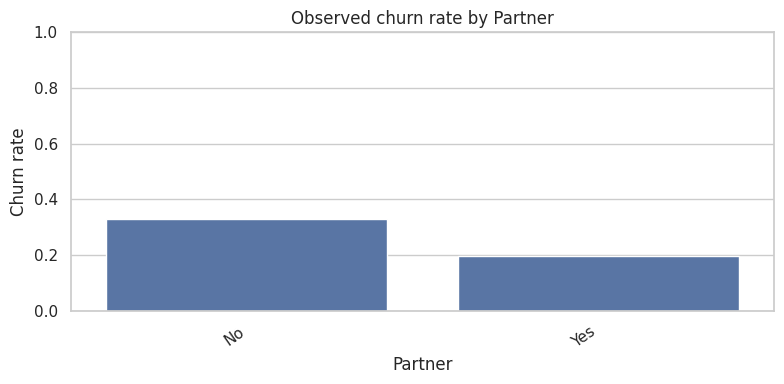

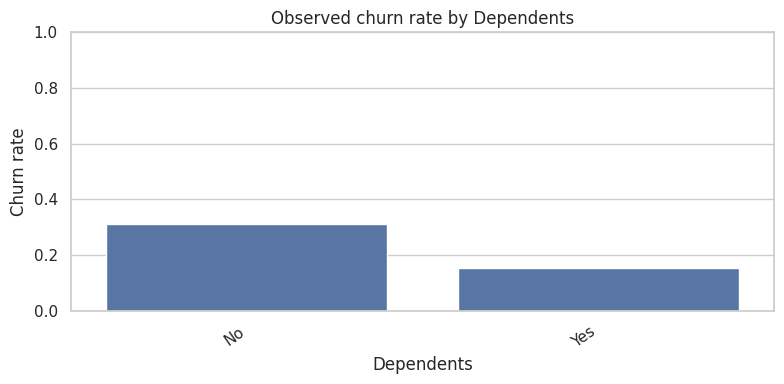

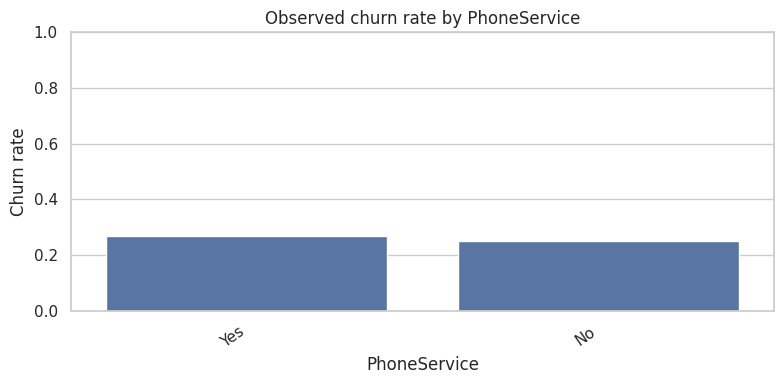

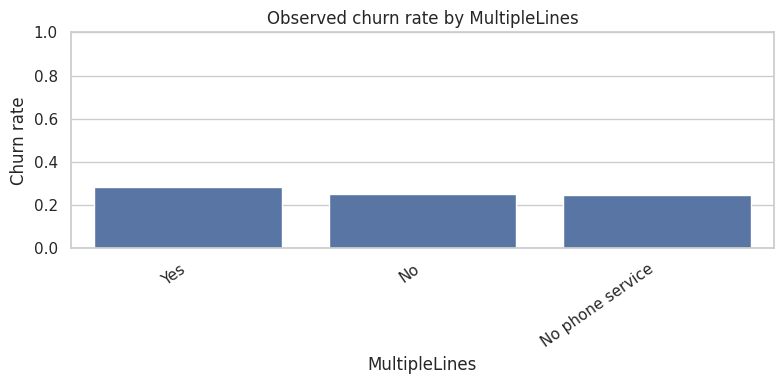

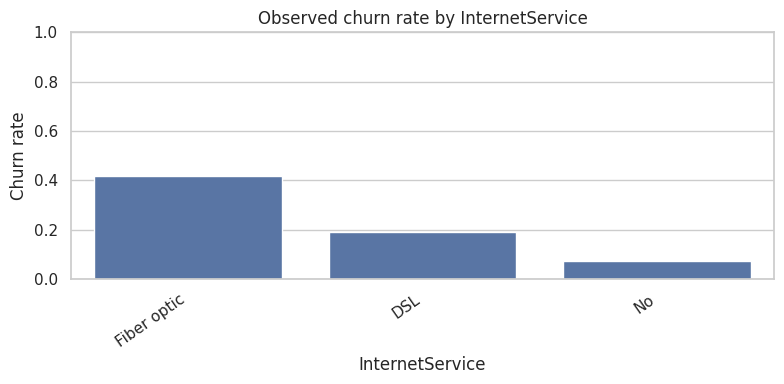

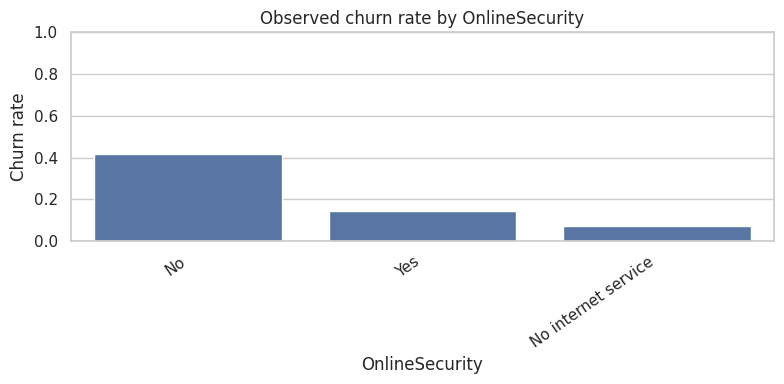

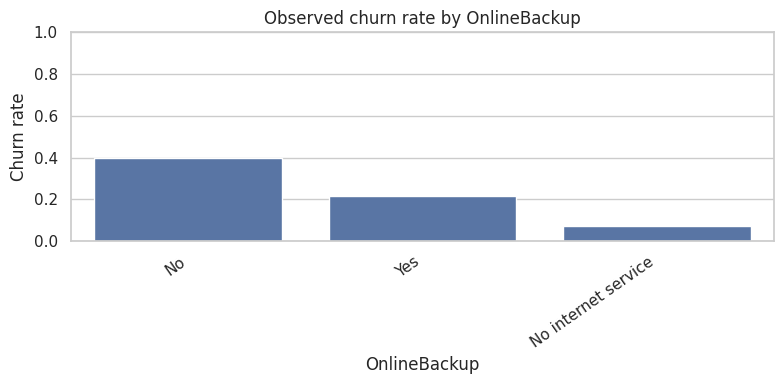

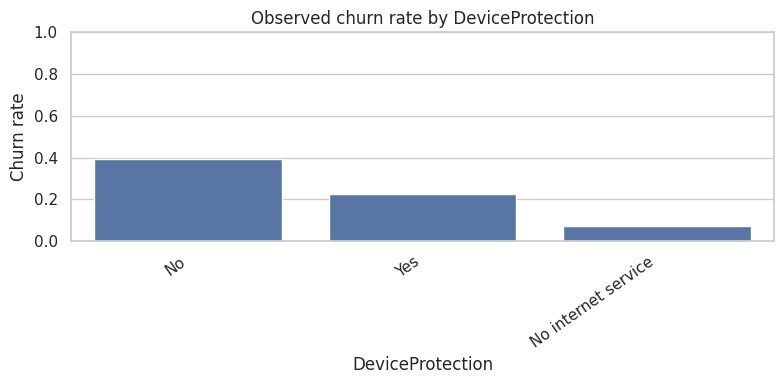

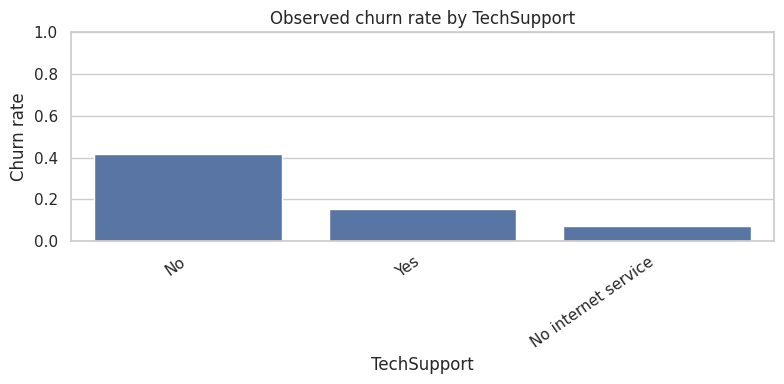

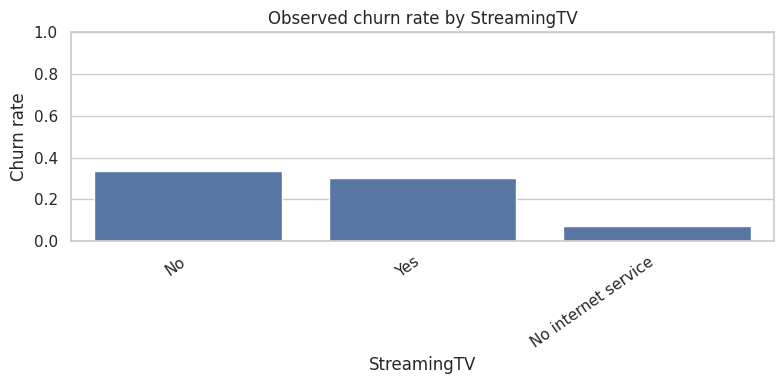

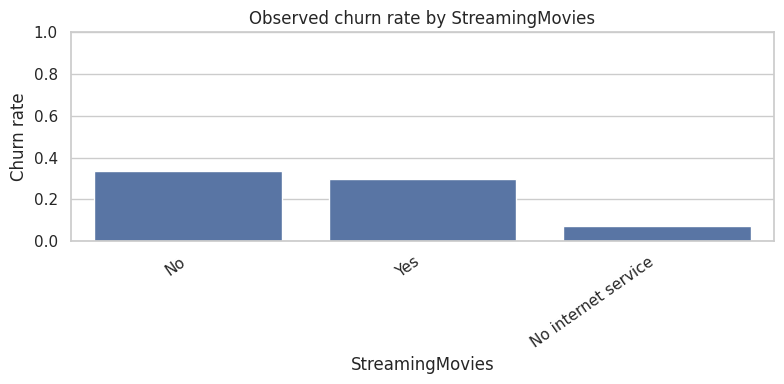

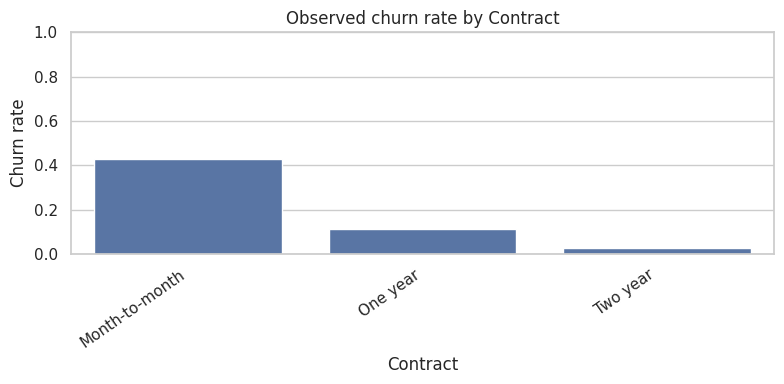

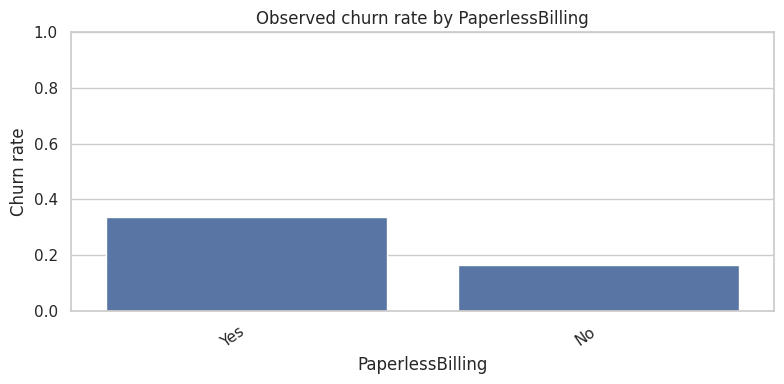

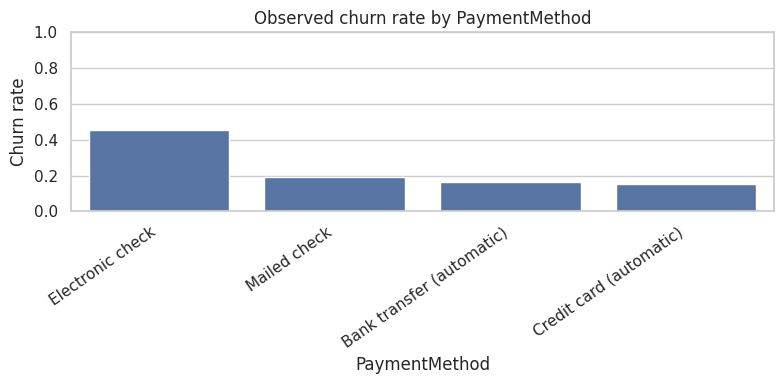

In [55]:
categorical_eda = [c for c in data.select_dtypes(include="object").columns if c != "customerID"]
for col in categorical_eda:
    rate = data.groupby(col, dropna=False)["Churn"].mean().sort_values(ascending=False)
    if rate.size <= 12:
        plt.figure(figsize=(8,4))
        sns.barplot(x=rate.index.astype(str), y=rate.values)
        plt.title(f"Observed churn rate by {col}")
        plt.ylabel("Churn rate")
        plt.xticks(rotation=35, ha="right")
        plt.ylim(0, 1)
        plt.tight_layout()
        plt.show()


### EDA interpretation prompts
- Compare churn rates across contract types and tenure bands.
- Check whether high monthly charges alone explain churn, or whether contract and service mix matter.
- Treat group differences as associations, not causal effects.


In [56]:
data["TenureGroup"] = pd.cut(
    data["tenure"], bins=[-1, 6, 12, 24, 48, 72],
    labels=["0–6", "7–12", "13–24", "25–48", "49–72"]
)
display(data.groupby("TenureGroup", observed=False)["Churn"].agg(["count","mean"]).rename(columns={"mean":"churn_rate"}))


,count,churn_rate
TenureGroup,,
0–6,1481,0.529372
7–12,705,0.358865
13–24,1024,0.287109
25–48,1594,0.203890
49–72,2239,0.095132


## 6. Define features and holdout split
Split before fitting imputers, encoders, scalers, or models. Stratification preserves the approximate target ratio in both sets.

In [57]:
X = data.drop(columns=["Churn", "customerID", "TenureGroup"], errors="ignore")
y = data["Churn"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train churn rate:", y_train.mean().round(3), "Test churn rate:", y_test.mean().round(3))


Train: (5634, 19) Test: (1409, 19)
Train churn rate: 0.265 Test churn rate: 0.265


## 7. Preprocessing pipeline
Numeric columns: median imputation + standardization. Categorical columns: most-frequent imputation + one-hot encoding. `handle_unknown='ignore'` supports categories not seen during training.

In [58]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


## 8. Baseline and candidate models
We compare a majority-class baseline, Logistic Regression, and Random Forest. Recall, F1, ROC-AUC, and average precision are included because churn classes are not balanced. The test set is reserved for final evaluation.

In [59]:
models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    )
}


In [60]:
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "avg_precision": "average_precision"
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
fitted_models = {}

for name, estimator in models.items():
    pipe = Pipeline([
        ("preprocess", preprocessor),
        ("model", estimator)
    ])

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_rows.append({
        "Model": name,
        **{
            metric: scores[f"test_{metric}"].mean()
            for metric in scoring
        },
        "ROC-AUC std": scores["test_roc_auc"].std()
    })

    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe

cv_results = (
    pd.DataFrame(cv_rows)
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)

display(
    cv_results.style.format(
        {
            "accuracy": "{:.3f}",
            "precision": "{:.3f}",
            "recall": "{:.3f}",
            "f1": "{:.3f}",
            "roc_auc": "{:.3f}",
            "avg_precision": "{:.3f}",
            "ROC-AUC std": "{:.3f}"
        }
    )
)


,Model,accuracy,precision,recall,f1,roc_auc,avg_precision,ROC-AUC std
0,Logistic Regression,0.748,0.516,0.801,0.628,0.846,0.660,0.012
1,Random Forest,0.787,0.591,0.640,0.615,0.837,0.639,0.009
2,Dummy (most frequent),0.735,0.000,0.000,0.000,0.500,0.265,0.000


## 9. Select a model using validation results
Choose based on the business objective and cross-validation evidence, not accuracy alone. This notebook selects the highest mean CV ROC-AUC as a reproducible default; you can change the criterion after reviewing recall/precision trade-offs.

In [61]:
selected_name = cv_results.iloc[0]["Model"]
best_model = fitted_models[selected_name]
print("Selected by mean CV ROC-AUC:", selected_name)


Selected by mean CV ROC-AUC: Logistic Regression


## 10. Final holdout evaluation

In [62]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "Average Precision": average_precision_score(y_test, y_prob)
}
display(pd.Series(metrics, name="Holdout score").to_frame().style.format("{:.3f}"))
print(classification_report(y_test, y_pred, target_names=["No churn", "Churn"], zero_division=0))


,Holdout score
Accuracy,0.738
Precision,0.504
Recall,0.783
F1,0.614
ROC-AUC,0.841
Average Precision,0.633


              precision    recall  f1-score   support

    No churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



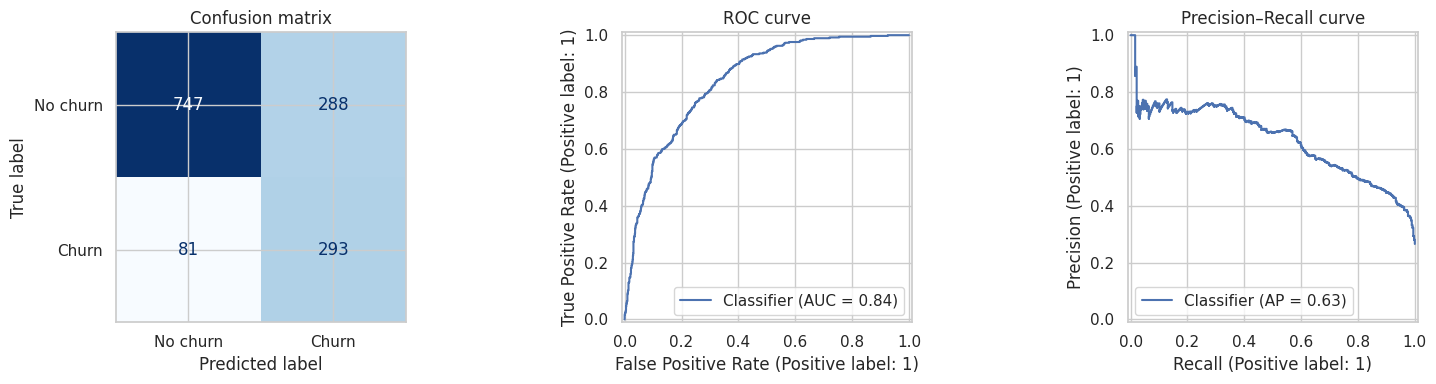

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No churn","Churn"], cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix")
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[2])
axes[2].set_title("Precision–Recall curve")
plt.tight_layout()
plt.show()


## 11. Threshold analysis
The default probability threshold is 0.50. A retention team may prefer a lower threshold to catch more at-risk customers, accepting more false positives. The analysis below searches for the highest threshold that reaches a target recall of 0.80. This is a transparent test-set diagnostic; in a production workflow, choose the threshold using validation data and evaluate it once on an untouched test set.


,threshold,precision,recall,f1,flagged_customers
0,0.20,0.389,0.963,0.554,926
1,0.21,0.393,0.963,0.559,915
2,0.22,0.397,0.957,0.562,901
3,0.23,0.401,0.949,0.563,886
4,0.24,0.405,0.947,0.567,875
...,...,...,...,...,...
56,0.76,0.663,0.479,0.556,270
57,0.77,0.677,0.460,0.548,254
58,0.78,0.690,0.447,0.542,242
59,0.79,0.694,0.425,0.527,229


Target recall: 0.80
Chosen operating threshold: 0.48
Recall at chosen operating threshold: 0.802


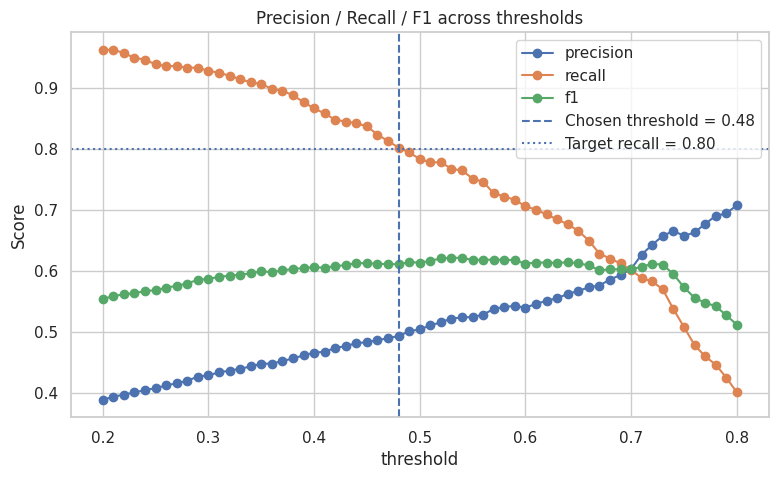

In [64]:
# Threshold analysis
# This is a transparent test-set diagnostic.
# In a production workflow, choose the operating threshold on validation data
# and evaluate it once on an untouched test set.

threshold_rows = []

for threshold in np.arange(0.20, 0.801, 0.01):
    pred_t = (y_prob >= threshold).astype(int)

    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "precision": precision_score(y_test, pred_t, zero_division=0),
        "recall": recall_score(y_test, pred_t, zero_division=0),
        "f1": f1_score(y_test, pred_t, zero_division=0),
        "flagged_customers": int(pred_t.sum())
    })

threshold_df = pd.DataFrame(threshold_rows)

# Choose the highest threshold that still reaches the target recall.
# This favors fewer false positives while maintaining the desired recall target.
target_recall = 0.80

eligible = threshold_df[threshold_df["recall"] >= target_recall]

if not eligible.empty:
    chosen_threshold = float(eligible.iloc[-1]["threshold"])
else:
    chosen_threshold = float(
        threshold_df.iloc[
            (threshold_df["recall"] - target_recall).abs().argsort().iloc[0]
        ]["threshold"]
    )

chosen_pred = (y_prob >= chosen_threshold).astype(int)

chosen_threshold_metrics = {
    "Precision": precision_score(y_test, chosen_pred, zero_division=0),
    "Recall": recall_score(y_test, chosen_pred, zero_division=0),
    "F1": f1_score(y_test, chosen_pred, zero_division=0),
}

display(threshold_df.round(3))

print(f"Target recall: {target_recall:.2f}")
print(f"Chosen operating threshold: {chosen_threshold:.2f}")
print(
    f"Recall at chosen operating threshold: "
    f"{chosen_threshold_metrics['Recall']:.3f}"
)

threshold_df.set_index("threshold")[["precision", "recall", "f1"]].plot(
    figsize=(9, 5),
    marker="o"
)
plt.axvline(
    chosen_threshold,
    linestyle="--",
    label=f"Chosen threshold = {chosen_threshold:.2f}"
)
plt.axhline(
    target_recall,
    linestyle=":",
    label=f"Target recall = {target_recall:.2f}"
)
plt.title("Precision / Recall / F1 across thresholds")
plt.ylabel("Score")
plt.legend()
plt.show()


## 12. Error analysis

In [65]:
error_review = X_test.copy()
error_review["actual_churn"] = y_test.values
error_review["predicted_churn"] = y_pred
error_review["churn_probability"] = y_prob
error_review["error_type"] = np.select(
    [(y_test.values == 1) & (y_pred == 0), (y_test.values == 0) & (y_pred == 1)],
    ["False negative (missed churn)", "False positive (unneeded flag)"],
    default="Correct"
)
display(error_review[error_review["error_type"] != "Correct"].sort_values("churn_probability", ascending=False).head(15))
display(error_review["error_type"].value_counts().to_frame("count"))


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,actual_churn,predicted_churn,churn_probability,error_type
3346,Female,1,No,No,2,Yes,Yes,Fiber optic,No,No,No,No,No,Yes,Month-to-month,Yes,Electronic check,84.05,186.05,0,1,0.920248,False positive (unneeded flag)
4039,Male,0,No,No,7,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,94.10,701.30,0,1,0.918097,False positive (unneeded flag)
935,Female,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,83.25,308.05,0,1,0.915773,False positive (unneeded flag)
5019,Male,1,No,No,14,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.60,1273.30,0,1,0.911573,False positive (unneeded flag)
352,Female,1,No,No,7,Yes,No,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,89.15,574.35,0,1,0.906909,False positive (unneeded flag)
2519,Male,0,Yes,No,2,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,No,Month-to-month,Yes,Electronic check,91.45,171.45,0,1,0.901260,False positive (unneeded flag)
2350,Female,0,No,No,5,Yes,Yes,Fiber optic,No,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,84.00,424.75,0,1,0.898171,False positive (unneeded flag)
6574,Female,1,No,No,9,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,No,Month-to-month,Yes,Electronic check,90.10,816.80,0,1,0.896302,False positive (unneeded flag)
5627,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,74.85,485.25,0,1,0.887182,False positive (unneeded flag)
5839,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,75.40,533.05,0,1,0.886930,False positive (unneeded flag)


,count
error_type,
Correct,1040
False positive (unneeded flag),288
False negative (missed churn),81


## 13. Permutation feature importance
Permutation importance is measured on held-out data and reflects how much the chosen metric drops when a feature is shuffled. Correlated features can share or mask importance; interpret as model reliance, not causality.

,mean ROC-AUC decrease
tenure,0.150130
InternetService,0.042216
Contract,0.040020
MonthlyCharges,0.038796
TotalCharges,0.010434
StreamingMovies,0.004437
OnlineSecurity,0.004180
StreamingTV,0.003944
TechSupport,0.003580
PaymentMethod,0.003283


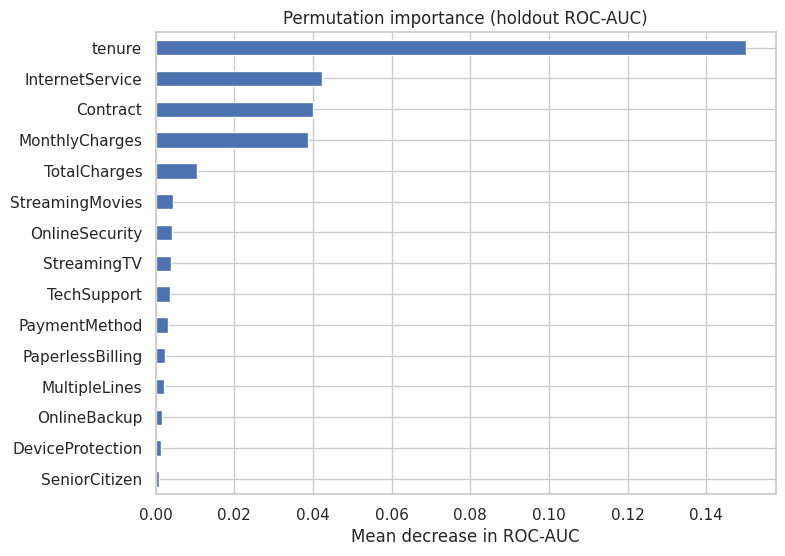

In [66]:
perm = permutation_importance(
    best_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE,
    scoring="roc_auc", n_jobs=-1
)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
display(importance.to_frame("mean ROC-AUC decrease").head(15))
importance.head(15).sort_values().plot(kind="barh", figsize=(8,6))
plt.title("Permutation importance (holdout ROC-AUC)")
plt.xlabel("Mean decrease in ROC-AUC")
plt.show()


## 14. Example scoring and export

In [67]:
# Example: score a few held-out customers
sample = X_test.head(5).copy()
sample_results = sample.copy()
sample_results["churn_probability"] = best_model.predict_proba(sample)[:, 1]
sample_results["predicted_churn_at_0.50"] = best_model.predict(sample)
display(sample_results)

os.makedirs("artifacts", exist_ok=True)
joblib.dump(best_model, "artifacts/telco_churn_pipeline.joblib")
print("Saved complete preprocessing + model pipeline.")


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,churn_probability,predicted_churn_at_0.50
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,0.115472,0
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0.853079,1
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20,0.146831,0
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,Yes,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75,0.660663,1
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,0.060436,0


Saved complete preprocessing + model pipeline.


In [68]:
# ============================================================
# 15. Final Model Summary
# ============================================================

final_model_name = selected_name

final_metrics = {
    "Accuracy": metrics["Accuracy"],
    "Precision": metrics["Precision"],
    "Recall": metrics["Recall"],
    "F1": metrics["F1"],
    "ROC-AUC": metrics["ROC-AUC"],
    "Average Precision": metrics["Average Precision"],
}

# The importance object is a Series indexed by feature name.
most_reliant_feature = importance.index[0]

print("Final Model Summary")
print("=" * 60)

print(f"Selected Model: {final_model_name}")
print()

print("Holdout Performance:")
for metric_name, value in final_metrics.items():
    print(f"- {metric_name}: {value:.3f}")

print()
print(f"Chosen Operating Threshold: {chosen_threshold:.2f}")
print(
    f"Recall at Chosen Operating Threshold: "
    f"{chosen_threshold_metrics['Recall']:.3f}"
)

print()
print("Most Relied-on Feature:")
print(f"- {most_reliant_feature}")

print()
print("Interpretation:")
print(
    f"{final_model_name} was selected as the final model based on the "
    "cross-validation results. On the holdout test set, the model achieved "
    f"a ROC-AUC of {final_metrics['ROC-AUC']:.3f} and an Average Precision "
    f"of {final_metrics['Average Precision']:.3f}. "
    f"Using the transparent threshold diagnostic, the chosen operating "
    f"threshold was {chosen_threshold:.2f}, producing a recall of "
    f"{chosen_threshold_metrics['Recall']:.3f}. "
    f"The feature with the highest permutation-based model reliance was "
    f"{most_reliant_feature}."
)


Final Model Summary
Selected Model: Logistic Regression

Holdout Performance:
- Accuracy: 0.738
- Precision: 0.504
- Recall: 0.783
- F1: 0.614
- ROC-AUC: 0.841
- Average Precision: 0.633

Chosen Operating Threshold: 0.48
Recall at Chosen Operating Threshold: 0.802

Most Relied-on Feature:
- tenure

Interpretation:
Logistic Regression was selected as the final model based on the cross-validation results. On the holdout test set, the model achieved a ROC-AUC of 0.841 and an Average Precision of 0.633. Using the transparent threshold diagnostic, the chosen operating threshold was 0.48, producing a recall of 0.802. The feature with the highest permutation-based model reliance was tenure.
